# CD2 — FAST2 đệ quy và GIF65 cho khử sương trên FPGA

**Câu hỏi nghiên cứu:** FAST2 nhìn trước 1 hàng giữ chất lượng gần GIF65 đến mức nào khi ưu tiên giảm bộ đệm của khối tinh chỉnh transmission?

Notebook gồm hai phép thử độc lập: (1) kiểm chứng RGB của build HLS với Python fixed-point trên cùng một ảnh; (2) đánh giá chất lượng so với GT và runtime lọc Python trên SOTS. Sửa đường dẫn và chọn đúng cấu hình build ở mục 2, rồi **Restart Kernel → Run All**. Có thể chạy thử vài ảnh trước bằng SAMPLE_LIMIT.

## 1. Mô hình và bài toán tối ưu

Mô hình sương: $I=Jt+A(1-t)$. Từ ảnh có sương $I$, dùng DCP15 và histogram để tạo $A$ và $t$ thô. Hai nhánh chỉ khác bộ lọc $t$. Khôi phục $J$ bằng $A+(I-A)/\max(t_{\mathrm{eff}},t_0)$, với $t_{\mathrm{eff}}$ là transmission đã lọc, cộng offset của build và chặn trên tại 1.

FAST2 dùng phép trộn $B(c,n,g)=c+g(n-c)$ theo hướng ngang thuận/ngược và dọc thuận, sau đó nhìn trước một hàng. Với $f_y$ là kết quả dọc thuận, đầu ra dọc là $B(f_y,f_{y+1},g_y)$; hàng cuối giữ $f_y$. Gain lấy từ chênh lệch RGB. Q12 có 12 bit phần lẻ; LUT gain Q8 và các phép làm tròn được giữ trong model fixed.

GIF65 dùng guide gray. Trong mỗi cửa sổ $65\times65$, $a=\operatorname{cov}(I_g,t)/(\operatorname{var}(I_g)+\epsilon)$, $b=\bar t-a\bar I_g$, và đầu ra là $\bar a I_g+\bar b$. Trung bình dùng biên reflect101.

**Hàm mục tiêu thiết kế:** giảm BRAM của M6 với ràng buộc mức giảm PSNR, SSIM trung bình trên từng tập không vượt ngưỡng chấp nhận và thông lượng đáp ứng yêu cầu.


## 2. Cấu hình

Notebook dùng **ω = 0,82** và **bù +492 Q14**. Offset được cộng sau M6, chặn tại 16384, rồi mới áp ngưỡng `t0` trong reconstruction. M6 giữ FAST2 nhìn trước 1 hàng, σ=6 và λ=1024.

In [1]:
from pathlib import Path
from PIL import Image
from IPython.display import display
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import cv2
except ImportError as exc:
    raise ImportError("Cần opencv-python; không cần OpenCV contrib/ximgproc") from exc

ROOT = Path(r"D:\semester_9\chuyende_2\CD2_final")
INPUT_PATH = ROOT / "hls_output" / "input.ppm"
HLS_OUTPUT_PATH = ROOT / "hls_output" / "output_hls.ppm"
HLS_FRAME_INDEX = 1   # 0=A_seed; 1=frame thứ hai của cùng ảnh, không reset DUT.
EXPECTED_SIZE = (1920, 1080)  # (width,height); None chỉ khi HLS cũng đổi kích thước test.
A_SEED = (210, 215, 220)
DCP_SIZE = 15
OMEGA = 0.82
T0 = 0.10
WLS_LAMBDA = 1024.0
WLS_SIGMA = 6.0
WLS_LAG = 1
STATE_FRAC_BITS = 12
CROP_FRAC = (0.15, 0.45, 0.90, 0.98)
DIFF_RGB_MAX = 8.0
SHOW_T_MAPS = True

if (DCP_SIZE, OMEGA, T0, WLS_LAMBDA, WLS_SIGMA, WLS_LAG, STATE_FRAC_BITS) != (
    15, 0.82, 0.10, 1024.0, 6.0, 1, 12
):
    raise ValueError("Mô hình fixed chỉ khớp cấu hình HLS FAST2_TIMING1_S6_L1024 đã gửi")
if HLS_FRAME_INDEX not in (0, 1):
    raise ValueError("Chọn frame 0 hoặc frame 1 của hai lần đưa cùng ảnh vào DUT")
if DIFF_RGB_MAX <= 0:
    raise ValueError("DIFF_RGB_MAX phải >0")

MODEL_ID = "FAST2_TIMING1_S6_L1024"
print("MODEL:", MODEL_ID)

OFFSET_Q14 = 492  # p7_full_dehaze.cpp: cộng sau M6.
RUN_HLS_CHECK = True
RUN_SOTS = True
DATA_ROOT = ROOT / "data"
SOTS_DIR = DATA_ROOT / "SOTS" if (DATA_ROOT / "SOTS").is_dir() else DATA_ROOT
SOTS_ROOTS = {
    "Indoor": SOTS_DIR / "indoor",
    "Outdoor": SOTS_DIR / "outdoor",
}
SAMPLE_LIMIT = None  # None: đủ 500 ảnh/tập; số nhỏ: chạy thử.
REPEATS = 3
if OFFSET_Q14 != 492:
    raise ValueError("Kiểm tra cấu hình omega và offset của build.")
print(f"Python profile: omega={OMEGA}, offset={OFFSET_Q14} Q14")

MODEL: FAST2_TIMING1_S6_L1024
Python profile: omega=0.82, offset=492 Q14


## 3. Model dùng chung
DCP, histogram, số học fixed-point, bộ lọc FAST2 và thước đo độ khớp.

In [2]:
def _assert_rgb_u8(rgb):
    rgb = np.asarray(rgb)
    if rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError(f"Expected HxWx3 RGB, got {rgb.shape}")
    if rgb.dtype != np.uint8:
        rgb = np.clip(rgb, 0, 255).astype(np.uint8)
    return rgb

def dark_channel_u8(rgb_u8, patch_size=15):
    """
    Raw Dark15 used by atmospheric-light estimation.
    Outside-image samples are virtual 255, matching truncated min-window behavior.
    """
    rgb_u8 = _assert_rgb_u8(rgb_u8)
    min_rgb = np.min(rgb_u8, axis=2).astype(np.uint8)
    kernel = np.ones((patch_size, patch_size), dtype=np.uint8)

    return cv2.erode(
        min_rgb,
        kernel,
        borderType=cv2.BORDER_CONSTANT,
        borderValue=255,
    )

def atmospheric_scalar_u8(A_rgb):
    """
    Note-1 scalar atmospheric light.
    Integer policy matches the intended once-per-frame HLS operation:
        A_scalar = round((Ar + Ag + Ab) / 3)
    This is a hardware approximation when Ar, Ag and Ab are different.
    """
    A = np.asarray(A_rgb, dtype=np.uint16).reshape(-1)
    if A.size != 3:
        raise ValueError(f"Expected 3-channel A, got shape {A.shape}")
    return int(np.clip((int(A.sum()) + 1) // 3, 1, 255))

def note1_transmission_from_raw_dark(dark_raw_u8, A_used, omega=OMEGA):
    """Create Note-1 t_coarse without a second normalized Dark15."""
    dark_raw = np.asarray(dark_raw_u8, dtype=np.uint8)
    A_scalar = atmospheric_scalar_u8(A_used)
    dark_raw_norm = dark_raw.astype(np.float64) / float(A_scalar)
    t_coarse = np.clip(1.0 - float(omega) * dark_raw_norm, 0.0, 1.0)
    return A_scalar, dark_raw_norm, t_coarse

def estimate_A_hls_histogram(rgb_u8, dark_u8, top_n=1):
    """
    Python model of CURRENT HLS histogram policy:
    per dark bin -> count + brightest RGB + largest {x,y} key on brightness tie.
    """
    rgb = _assert_rgb_u8(rgb_u8)
    dark = np.asarray(dark_u8, dtype=np.uint8)

    H, W = dark.shape
    dflat = dark.ravel()
    brightness = rgb.astype(np.uint16).sum(axis=2).ravel().astype(np.int32)

    yy, xx = np.indices((H, W), dtype=np.int32)
    coord = ((xx << 11) | yy).ravel().astype(np.int64)

    counts = np.bincount(dflat, minlength=256).astype(np.int64)

    max_b = np.full(256, -1, dtype=np.int32)
    np.maximum.at(max_b, dflat, brightness)

    eligible = brightness == max_b[dflat]
    max_coord = np.full(256, -1, dtype=np.int64)
    np.maximum.at(max_coord, dflat[eligible], coord[eligible])

    cumulative = 0
    threshold = 0
    threshold_count = 0

    for d in range(255, -1, -1):
        nxt = cumulative + int(counts[d])
        if nxt >= top_n:
            threshold = d
            threshold_count = nxt
            break
        cumulative = nxt

    chosen_d = None
    chosen_brightness = -1

    for d in range(255, threshold - 1, -1):
        if counts[d] == 0:
            continue
        if int(max_b[d]) > chosen_brightness:
            chosen_brightness = int(max_b[d])
            chosen_d = d

    if chosen_d is None:
        A = np.array([1, 1, 1], dtype=np.uint8)
        chosen_xy = (-1, -1)
    else:
        key = int(max_coord[chosen_d])
        x = key >> 11
        y = key & ((1 << 11) - 1)
        chosen_xy = (x, y)
        A = np.maximum(rgb[y, x], 1).astype(np.uint8)

    return A, {
        "threshold": int(threshold),
        "threshold_count": int(threshold_count),
        "top_n": int(top_n),
        "pixel": chosen_xy,
        "brightness": int(chosen_brightness),
        "dark_bin": None if chosen_d is None else int(chosen_d),
    }

def reconstruct_float(rgb,t,A_used):
    A=np.asarray(A_used,dtype=np.float64).reshape(1,1,3)
    j=(np.asarray(rgb,dtype=np.float64)-A)/np.maximum(t,T0)[...,None]+A
    return np.floor(np.clip(j,0,255)+.5).astype(np.uint8)

In [3]:
def round_shift_even(x, bits):
    """AP_RND_CONV for nonnegative integer raw values."""
    x=np.asarray(x,dtype=np.int64)
    if np.any(x<0) or bits<0:
        raise ValueError("round_shift_even expects nonnegative x and bits>=0")
    if bits==0:return x.copy()
    base=x>>bits;rem=x- (base<<bits);half=1<<(bits-1)
    return base+((rem>half)|((rem==half)&((base&1)!=0)))

def coarse_hls_raw(dark,A_used):
    """Exact M5 scalar-A LUT and casts for the selected omega; returns Q2.14 raw."""
    A_scalar=atmospheric_scalar_u8(A_used)
    invA=int(np.rint((1<<23)/A_scalar))
    work=round_shift_even(np.asarray(dark,dtype=np.int64)*invA,6) # Q9.17
    work=np.minimum(work,int(np.rint(1.999*(1<<17))))
    normalized=round_shift_even(work,3) # Q2.14
    omega_raw=int(np.rint(OMEGA*(1<<17)))
    omega_min=round_shift_even(normalized*omega_raw,12) # Q3.19
    twork=np.clip((1<<19)-omega_min,0,1<<19)
    return round_shift_even(twork,5).astype(np.uint16)

def reconstruct_hls(rgb,t_raw,A_used):
    """Integer model of reciprocal LUT + one Newton step and RGB recovery."""
    if T0!=0.10:raise ValueError("Fixed model matches supplied t0=0.10 source only")
    raw=np.asarray(t_raw,dtype=np.int64)
    if np.any((raw<0)|(raw>16384)):raise ValueError("Bad raw t")
    t=np.maximum(raw,int(np.rint(.1*16384)))
    shift=np.where(t>=8192,0,np.where(t>=4096,1,np.where(t>=2048,2,3)))
    m=t<<(3+shift) # Q1.17
    seed=np.array([130056,128070,126144,124276,122461,120699,118987,117323,
        115705,114131,112599,111107,109655,108240,106861,105517,
        104206,102928,101680,100462,99273,98112,96978,95870,
        94787,93727,92692,91679,90688,89718,88768,87839,
        86929,86037,85164,84308,83469,82646,81840,81049,
        80274,79513,78766,78034,77314,76608,75915,75234,
        74565,73908,73263,72629,72005,71392,70790,70198,
        69615,69042,68478,67924,67378,66841,66313,65793],dtype=np.int64)
    x0=seed[(m>>10)&63] # Q2.16
    mx=round_shift_even(m*x0,12) # Q3.21
    corr=round_shift_even((2<<21)-mx,5) # Q2.16
    x1p=round_shift_even(x0*corr,11) # Q3.21
    x1=round_shift_even(x1p,5) # Q2.16
    inv=(x1<<1)<<shift # Q5.17
    inv=np.where(t>=16384,1<<17,inv) # unity guard in source
    A=np.asarray(A_used,dtype=np.int64).reshape(1,1,3)
    j=(np.asarray(rgb,dtype=np.int64)-A)*inv[...,None]+(A<<17)
    J=np.clip((j+(1<<16))>>17,0,255).astype(np.uint8)
    return J,inv


def compensate_q14(raw):
    return np.minimum(raw.astype(np.int32) + OFFSET_Q14, 16384).astype(np.uint16)

In [4]:
"""FAST2 integer/float recursive models. Display-only callers; no file writes.
Fixed gains approximate the steady-state WLS solution in constant-weight regions.
Variable weights and fixed vertical look-ahead make this different from FGS/WLS.
"""
import math
import numpy as np
ONE=4096
WEIGHTS=np.array([math.floor(math.exp(-d/6.0)*ONE+.5) for d in range(73)],dtype=np.int64)
S=1024.0*WEIGHTS.astype(np.float64)/ONE
GAINS=np.floor(256*(2*S/(1+2*S+np.sqrt(1+4*S)))+.5).astype(np.int64)
assert len(GAINS)==73 and int(GAINS.sum())==9208
assert int(np.dot(np.arange(1,74,dtype=np.int64),GAINS))==197387
print("GAIN LUT: sigma6/lambda1024 | count=73 | sum=9208 | weighted=197387")

def edge_gain(rgb_a,rgb_b):
    delta=np.asarray(rgb_a,dtype=np.int64)-np.asarray(rgb_b,dtype=np.int64)
    distance=np.floor(np.sqrt(np.sum(delta*delta,axis=-1))+.5).astype(np.int64)
    return np.where(distance<73,GAINS[np.minimum(distance,72)],0)

def recursive_blend(a,center,neighbor):
    a=np.asarray(a,dtype=np.int64)
    center=np.asarray(center,dtype=np.int64)
    neighbor=np.asarray(neighbor,dtype=np.int64)
    return ((center<<8)+a*(neighbor-center)+128)>>8

def m6_model(rgb,t_raw_q14,return_stages=False):
    rgb=np.asarray(rgb,dtype=np.uint8)
    raw=np.asarray(t_raw_q14,dtype=np.int64)
    if rgb.shape!=raw.shape+(3,) or np.any(raw<0) or np.any(raw>16384):
        raise ValueError('Expected RGB HxWx3 and raw t Q2.14 in 0..16384')
    h,w=raw.shape
    if min(h,w)<2:raise ValueError('At least two rows/columns required')
    q=(raw+2)>>2
    horizontal=edge_gain(rgb[:,1:],rgb[:,:-1])
    for x in range(1,w):q[:,x]=recursive_blend(horizontal[:,x-1],q[:,x],q[:,x-1])
    hf=q.copy() if return_stages else None
    for x in range(w-2,-1,-1):q[:,x]=recursive_blend(horizontal[:,x],q[:,x],q[:,x+1])
    hb=q.copy() if return_stages else None
    result=np.empty_like(q)
    previous=q[0].copy()
    for y in range(1,h):
        gain=edge_gain(rgb[y],rgb[y-1])
        current=recursive_blend(gain,q[y],previous)
        result[y-1]=recursive_blend(gain,previous,current)
        previous=current
    result[-1]=previous
    output=(result<<2).astype(np.uint16)
    if return_stages:
        packed=rgb[...,0].astype(np.uint64)|(rgb[...,1].astype(np.uint64)<<8)|(rgb[...,2].astype(np.uint64)<<16)
        return output,dict(INPUT_T14=raw,GUIDE_RGB24=packed,HF_Q12=hf,HB_Q12=hb,OUTPUT_T14=output)
    return output

def m6_float(rgb,t,lam=1024.,sigma=6.):
    rgb=np.asarray(rgb,dtype=np.float64)
    q=np.asarray(t,dtype=np.float64).copy()
    def gain(a,b):
        s=lam*np.exp(-np.linalg.norm(a-b,axis=-1)/sigma)
        return 2*s/(1+2*s+np.sqrt(1+4*s))
    horizontal=gain(rgb[:,1:],rgb[:,:-1])
    for x in range(1,q.shape[1]):q[:,x]=(1-horizontal[:,x-1])*q[:,x]+horizontal[:,x-1]*q[:,x-1]
    for x in range(q.shape[1]-2,-1,-1):q[:,x]=(1-horizontal[:,x])*q[:,x]+horizontal[:,x]*q[:,x+1]
    result=np.empty_like(q)
    previous=q[0].copy()
    for y in range(1,q.shape[0]):
        a=gain(rgb[y],rgb[y-1]);current=(1-a)*q[y]+a*previous
        result[y-1]=(1-a)*previous+a*current;previous=current
    result[-1]=previous
    return np.clip(result,0,1)

# Marker prevents accidentally calling an old WLS function left in the kernel.
m6_model.model_id = "FAST2_TIMING1_S6_L1024"
m6_float.model_id = "FAST2_TIMING1_S6_L1024"

GAIN LUT: sigma6/lambda1024 | count=73 | sum=9208 | weighted=197387


In [5]:
def comparison_metrics(a,b):
    if a.shape!=b.shape:raise ValueError("Hai ảnh phải cùng kích thước")
    delta=a.astype(np.float64)-b.astype(np.float64)
    absolute=np.abs(delta);mse=float(np.mean(delta*delta))
    return dict(MAE=float(absolute.mean()),RMSE=float(np.sqrt(mse)),
        MAX_ABS=float(absolute.max()),MEAN_SIGNED=float(delta.mean()),
        CHANNEL_EXACT_PERCENT=100*float(np.mean(absolute==0)),
        PIXEL_EXACT_PERCENT=100*float(np.mean(np.all(absolute==0,axis=2))),
        CHANNEL_LE1_PERCENT=100*float(np.mean(absolute<=1)),
        PSNR_dB=np.inf if mse==0 else float(10*np.log10(255**2/mse)))

## 4. Kiểm chứng Python với build HLS hiện tại

Dùng đúng ảnh đưa vào DUT, đúng frame và cùng $A$. Frame index 1 giả sử đưa cùng ảnh hai lần không reset. Chỉ phần **HLS vs Python fixed** kiểm tra độ khớp đầu ra phần cứng; PSNR ở đây không phải PSNR so với GT.

In [6]:
if RUN_HLS_CHECK and INPUT_PATH.is_file():
    # Chỉ đọc input và output đã có. Không tự resize/đổi kích thước ảnh.
    if not INPUT_PATH.is_file():
        raise FileNotFoundError(f"Không thấy input: {INPUT_PATH}. Sửa INPUT_PATH.")
    with Image.open(INPUT_PATH) as image:
        rgb=np.array(image.convert("RGB"),dtype=np.uint8)
    h,w=rgb.shape[:2]
    if min(h,w)<15 or max(h,w)>2048:
        raise ValueError("Mỗi chiều cần 15..2048 cho mô hình tọa độ histogram HLS")
    if EXPECTED_SIZE is not None and (w,h)!=tuple(EXPECTED_SIZE):
        raise ValueError(f"Input là {w}x{h}; HLS đang cấu hình {EXPECTED_SIZE}. Không tự resize.")
    dark15=dark_channel_u8(rgb,15)
    # P7_TOP_N = WIDTH*HEIGHT/1000 trong header HLS.
    top_n=max(1,dark15.size//1000)
    A_estimated,A_info=estimate_A_hls_histogram(rgb,dark15,top_n=top_n)
    A_used=(np.array(A_SEED,dtype=np.uint8) if HLS_FRAME_INDEX==0 else A_estimated.copy())
    J_hls=None
    if HLS_OUTPUT_PATH is not None:
        hp=Path(HLS_OUTPUT_PATH)
        if hp.is_file():
            if hp.resolve()==INPUT_PATH.resolve():
                raise ValueError("HLS_OUTPUT_PATH đang trỏ vào chính input")
            with Image.open(hp) as image:
                J_hls=np.array(image.convert("RGB"),dtype=np.uint8)
            if J_hls.shape!=rgb.shape:
                raise ValueError(f"HLS shape {J_hls.shape} khác input {rgb.shape}; không tự resize")
        else:
            print("Chưa thấy output HLS:",hp)
    print("Input:",rgb.shape,"| HLS_FRAME_INDEX:",HLS_FRAME_INDEX)
    print("A ước lượng:",tuple(int(v) for v in A_estimated),"| thông tin:",A_info)
    print("A dùng để so sánh:",tuple(int(v) for v in A_used),
          "| A_scalar:",atmospheric_scalar_u8(A_used))
    print(f"DCP15 / omega{OMEGA} / offset{OFFSET_Q14} Q14 / FAST2 recursive lambda1024 sigma6 lag1 top-down / gain Q0.8, mean Q1.12 / t0=0.10")
    if J_hls is None:
        print("CHƯA CÓ KẾT QUẢ HLS: chỉ tính Python, chưa thể kết luận HLS khớp.")
    else:
        print("Đã đọc ảnh HLS. Chỉ dùng output mới của WLS, đúng input và đúng frame nêu trên.")

else:
    print("Bỏ qua kiểm chứng một ảnh: chưa bật hoặc chưa có INPUT_PATH.")

Input: (1080, 1920, 3) | HLS_FRAME_INDEX: 1
A ước lượng: (245, 246, 250) | thông tin: {'threshold': 242, 'threshold_count': 2480, 'top_n': 2073, 'pixel': (1125, 3), 'brightness': 741, 'dark_bin': 245}
A dùng để so sánh: (245, 246, 250) | A_scalar: 247
DCP15 / omega0.82 / offset492 Q14 / FAST2 recursive lambda1024 sigma6 lag1 top-down / gain Q0.8, mean Q1.12 / t0=0.10
Đã đọc ảnh HLS. Chỉ dùng output mới của WLS, đúng input và đúng frame nêu trên.


In [7]:
if RUN_HLS_CHECK and INPUT_PATH.is_file():
    if any(getattr(fn,"model_id",None)!=MODEL_ID for fn in (m6_model,m6_float)):
        raise RuntimeError("M6 trong kernel không phải FAST2_TIMING1_S6_L1024. Restart Kernel và Run All.")
    tic=time.perf_counter()
    coarse_fixed_raw=coarse_hls_raw(dark15,A_used)
    refined_fixed_raw,trace_stages=m6_model(rgb,coarse_fixed_raw,return_stages=True)
    J_fixed,inv_t_fixed=reconstruct_hls(rgb,compensate_q14(refined_fixed_raw),A_used)
    fixed_seconds=time.perf_counter()-tic

    tic=time.perf_counter()
    _,_,coarse_float=note1_transmission_from_raw_dark(dark15,A_used,omega=OMEGA)
    refined_float=m6_float(rgb,coarse_float,lam=WLS_LAMBDA,sigma=WLS_SIGMA)
    J_float=reconstruct_float(rgb,np.minimum(refined_float + OFFSET_Q14 / 16384, 1),A_used)
    float_seconds=time.perf_counter()-tic

    comparisons=[]
    if J_hls is not None:
        comparisons.extend([
            dict(comparison="HLS vs Python fixed",**comparison_metrics(J_hls,J_fixed)),
            dict(comparison="HLS vs Python float",**comparison_metrics(J_hls,J_float)),
        ])
    comparisons.append(dict(
        comparison="Python fixed vs Python float",**comparison_metrics(J_fixed,J_float)))
    audit_summary=pd.DataFrame(comparisons)
    display(audit_summary)
    print(f"Thời gian Python fixed: {fixed_seconds:.2f}s | float: {float_seconds:.2f}s")
    print("Thời gian Python không đại diện tốc độ FPGA.")
    if J_hls is not None:
        if np.array_equal(J_hls,J_fixed):
            print("PASS cho ảnh này: HLS và Python fixed khớp từng kênh, từng pixel.")
        else:
            print("CHƯA KHỚP BIT-EXACT: kiểm tra đúng bản FAST2 recursive, frame/A, input, LUT và làm tròn.")
            delta=J_hls.astype(np.int16)-J_fixed.astype(np.int16)
            iy,ix,ic=np.unravel_index(np.abs(delta).argmax(),delta.shape)
            print("Vị trí lệch lớn nhất (x,y,kênh RGB):",(int(ix),int(iy),int(ic)),
                  "| HLS:",J_hls[iy,ix].tolist(),"| Python fixed:",J_fixed[iy,ix].tolist())
    print("PSNR ở đây là độ khớp triển khai, KHÔNG phải chất lượng so với ảnh sạch.")

    fixed_t=refined_fixed_raw.astype(np.float64)/16384
    coarse_t=coarse_fixed_raw.astype(np.float64)/16384
    display(pd.DataFrame([dict(
        method="FAST2 fixed", t_mean=float(fixed_t.mean()),
        t_MAE_vs_coarse=float(np.mean(np.abs(fixed_t-coarse_t))),
        t_MAX_vs_coarse=float(np.max(np.abs(fixed_t-coarse_t))))]))
    print("Độ thay đổi t chỉ đo tác động lọc; cần nhìn crop/GT để đánh giá halo và chất lượng.")

,comparison,MAE,RMSE,MAX_ABS,MEAN_SIGNED,CHANNEL_EXACT_PERCENT,PIXEL_EXACT_PERCENT,CHANNEL_LE1_PERCENT,PSNR_dB
0,HLS vs Python fixed,0.000000,0.000000,0.0,0.000000,100.000000,100.000000,100.000000,inf
1,HLS vs Python float,0.065995,0.257066,5.0,0.024451,93.404482,83.516059,99.996367,59.929918
2,Python fixed vs Python float,0.065995,0.257066,5.0,0.024451,93.404482,83.516059,99.996367,59.929918


Thời gian Python fixed: 1.86s | float: 0.88s
Thời gian Python không đại diện tốc độ FPGA.
PASS cho ảnh này: HLS và Python fixed khớp từng kênh, từng pixel.
PSNR ở đây là độ khớp triển khai, KHÔNG phải chất lượng so với ảnh sạch.


,method,t_mean,t_MAE_vs_coarse,t_MAX_vs_coarse
0,FAST2 fixed,0.582152,0.016058,0.323486


Độ thay đổi t chỉ đo tác động lọc; cần nhìn crop/GT để đánh giá halo và chất lượng.


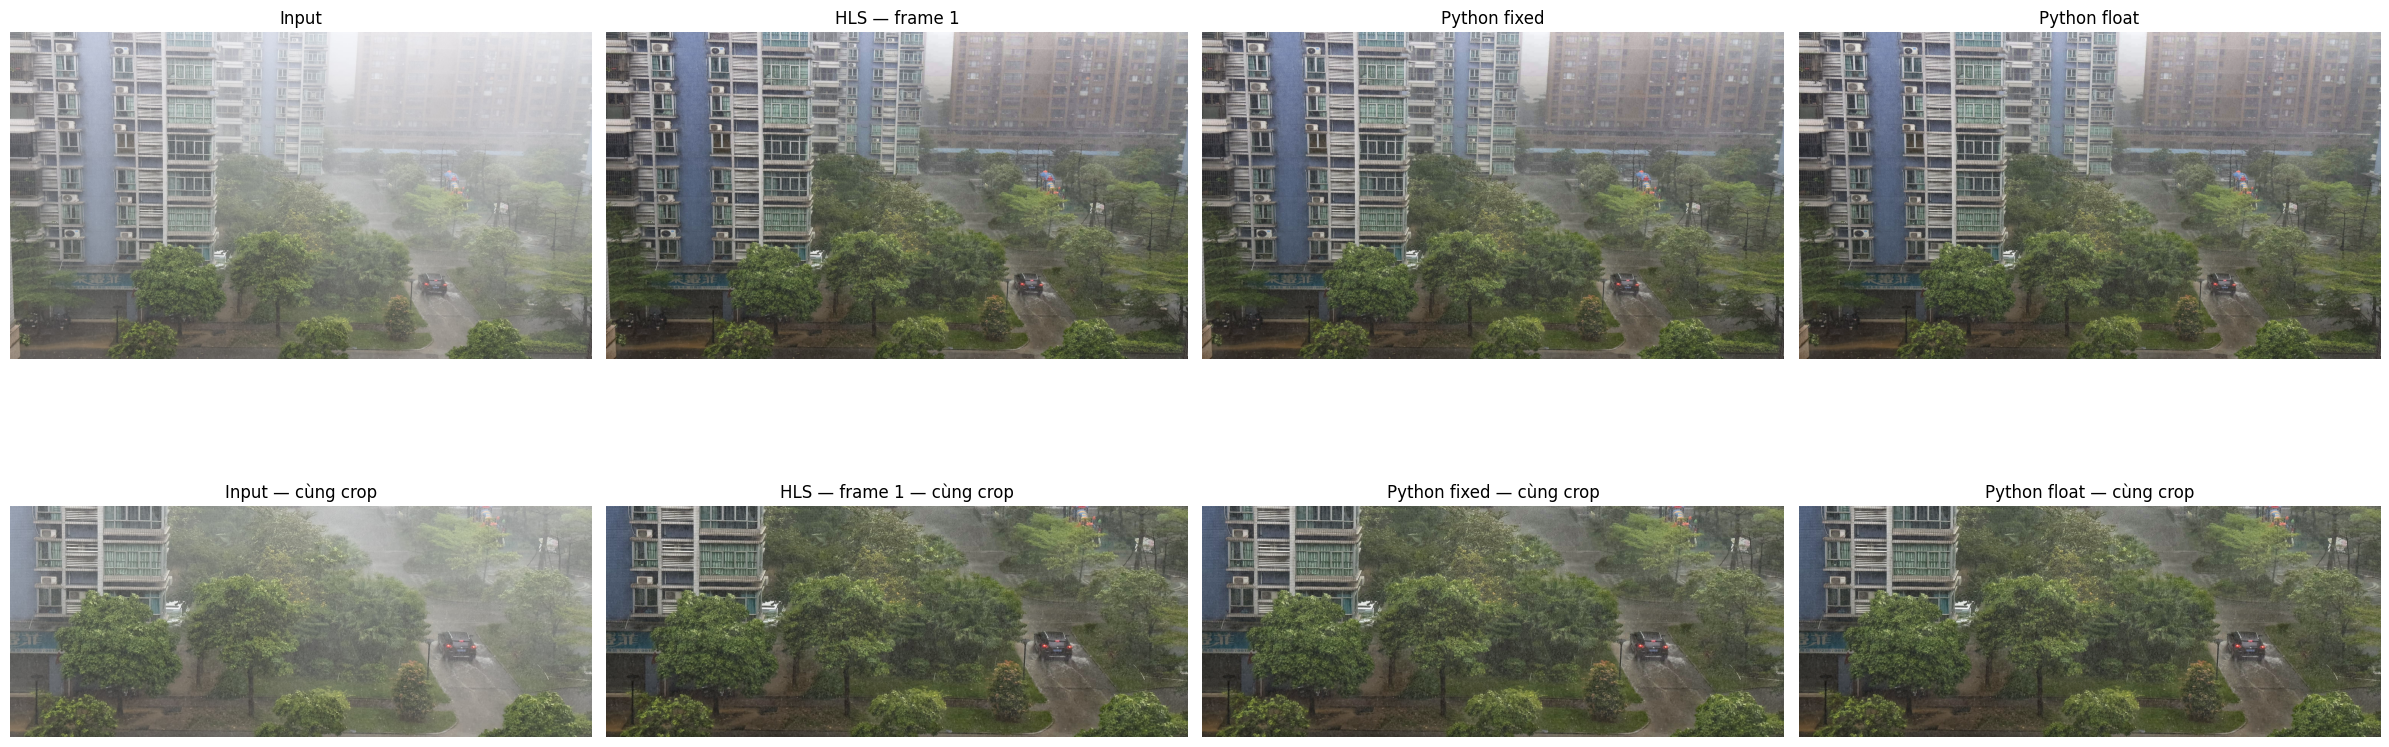

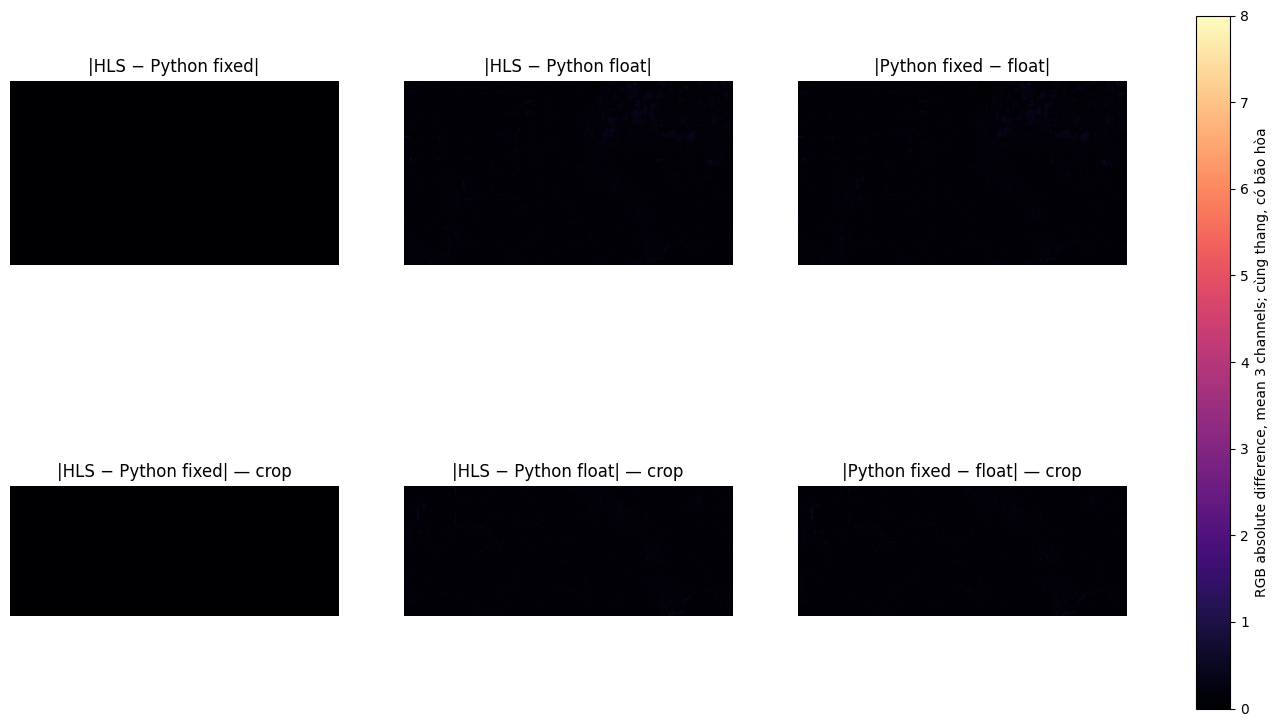

In [8]:
if RUN_HLS_CHECK and INPUT_PATH.is_file():
    # Hiển thị input, HLS (nếu có), Python fixed và Python float.
    fx0,fy0,fx1,fy1=CROP_FRAC
    if not (0<=fx0<fx1<=1 and 0<=fy0<fy1<=1):raise ValueError("CROP_FRAC không hợp lệ")
    xs=slice(int(fx0*w),max(int(fx0*w)+1,int(fx1*w)))
    ys=slice(int(fy0*h),max(int(fy0*h)+1,int(fy1*h)))
    items=[("Input",rgb)]
    if J_hls is not None:items.append(("HLS — frame "+str(HLS_FRAME_INDEX),J_hls))
    items.extend([("Python fixed",J_fixed),("Python float",J_float)])
    fig,axes=plt.subplots(2,len(items),figsize=(6*len(items),10),squeeze=False)
    for col,(name,img) in enumerate(items):
        axes[0,col].imshow(img);axes[0,col].set_title(name)
        axes[1,col].imshow(img[ys,xs]);axes[1,col].set_title(name+" — cùng crop")
    for ax in axes.ravel():ax.axis("off")
    plt.tight_layout();plt.show();plt.close(fig)

    differences=[]
    if J_hls is not None:
        differences.append(("|HLS − Python fixed|",np.abs(J_hls.astype(float)-J_fixed).mean(axis=2)))
        differences.append(("|HLS − Python float|",np.abs(J_hls.astype(float)-J_float).mean(axis=2)))
    differences.append(("|Python fixed − float|",np.abs(J_fixed.astype(float)-J_float).mean(axis=2)))
    fig,axes=plt.subplots(2,len(differences),figsize=(6*len(differences),9),squeeze=False)
    for col,(name,diff) in enumerate(differences):
        for row,crop in enumerate((False,True)):
            ax=axes[row,col]
            im=ax.imshow(diff[ys,xs] if crop else diff,cmap="magma",vmin=0,vmax=DIFF_RGB_MAX)
            ax.set_title(name+(" — crop" if crop else ""));ax.axis("off")
    fig.colorbar(im,ax=list(axes.ravel()),label="RGB absolute difference, mean 3 channels; cùng thang, có bão hòa")
    plt.show();plt.close(fig)

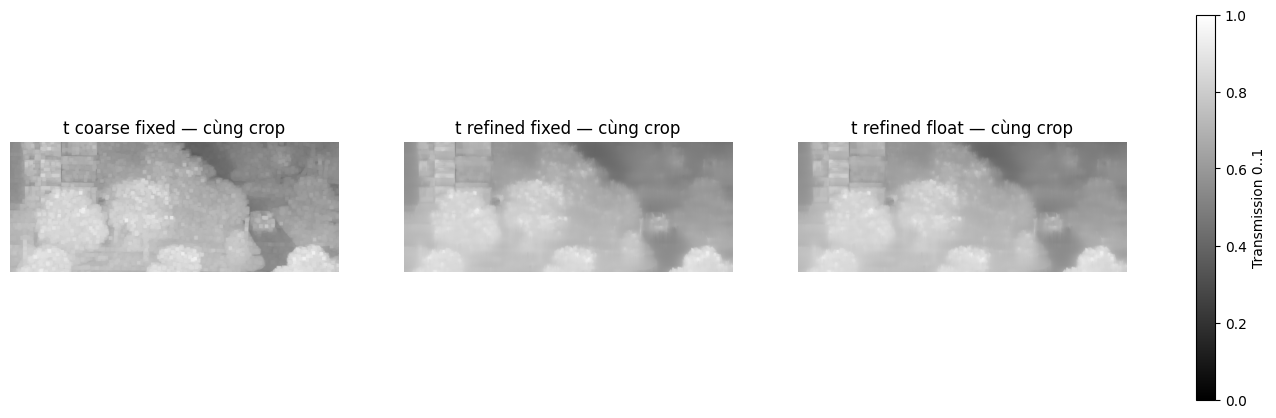

,method,t_min,t_mean,t_max
0,t coarse fixed,0.186646,0.582872,0.943542
1,t refined fixed,0.211182,0.582152,0.943604
2,t refined float,0.211181,0.582055,0.943563


Hoàn thành. Không ghi file ảnh, bảng số liệu hay cache ra ổ đĩa.


In [9]:
if RUN_HLS_CHECK and INPUT_PATH.is_file():
    # Chỉ có t từ mô hình Python; file HLS RGB không chứa t nội bộ.
    if SHOW_T_MAPS:
        fixed_t=refined_fixed_raw.astype(np.float64)/16384
        stages=[("t coarse fixed",coarse_fixed_raw.astype(float)/16384),
                ("t refined fixed",fixed_t),("t refined float",refined_float)]
        fig,axes=plt.subplots(1,3,figsize=(18,5))
        for ax,(name,t) in zip(axes,stages):
            im=ax.imshow(t[ys,xs],cmap="gray",vmin=0,vmax=1)
            ax.set_title(name+" — cùng crop");ax.axis("off")
        fig.colorbar(im,ax=list(axes),label="Transmission 0..1")
        plt.show();plt.close(fig)
        display(pd.DataFrame([dict(method=name,t_min=float(t.min()),t_mean=float(t.mean()),
                                  t_max=float(t.max())) for name,t in stages]))
    print("Hoàn thành. Không ghi file ảnh, bảng số liệu hay cache ra ổ đĩa.")

In [10]:
if RUN_HLS_CHECK and INPUT_PATH.is_file():
    # Chỉ hiển thị; không ghi file. So bảng này với TRACE frame=1 của C-sim.
    def stage_signature(values):
        v=np.asarray(values,dtype=np.uint64).reshape(-1)
        position=np.arange(1,v.size+1,dtype=np.uint64)
        return dict(count=int(v.size),
                    sum=int(v.sum(dtype=np.uint64)) & 0xffffffff,
                    weighted=int((v*position).sum(dtype=np.uint64)) & 0xffffffff)

    trace_table=pd.DataFrame([
        dict(stage=stage,**stage_signature(values))
        for stage,values in trace_stages.items()
    ])
    print("MODEL: FAST2_TIMING1_S6_L1024; arithmetic identical to FAST2")
    print("A_used:",tuple(int(v) for v in A_used),"| omega:",OMEGA,
          "| HLS_FRAME_INDEX:",HLS_FRAME_INDEX,"| input shape:",rgb.shape)
    display(trace_table)
    print("INPUT_T14: t coarse Q2.14 vào M6; GUIDE_RGB24: R ở 8 bit thấp.")
    print("HF_Q12: sau ngang thuận; HB_Q12: sau ngang ngược; OUTPUT_T14: t ra M6.")
    print("So đúng frame/A/input. Nếu INPUT/GUIDE trùng mà HF lệch, kiểm tra M6/LUT.")
    print("Nếu OUTPUT_T14 trùng mà RGB còn lệch, kiểm tra reconstruction hoặc file output đang đọc.")
    print("Checksum trùng không chứng minh từng pixel trùng; bảng RGB vẫn là kiểm tra cuối.")

MODEL: FAST2_TIMING1_S6_L1024; arithmetic identical to FAST2
A_used: (245, 246, 250) | omega: 0.82 | HLS_FRAME_INDEX: 1 | input shape: (1080, 1920, 3)


,stage,count,sum,weighted
0,INPUT_T14,2073600,2622558101,3679343831
1,GUIDE_RGB24,2073600,3866512150,1022576610
2,HF_Q12,2073600,679450511,4157391310
3,HB_Q12,2073600,672436845,3741969536
4,OUTPUT_T14,2073600,2598068304,2607574072


INPUT_T14: t coarse Q2.14 vào M6; GUIDE_RGB24: R ở 8 bit thấp.
HF_Q12: sau ngang thuận; HB_Q12: sau ngang ngược; OUTPUT_T14: t ra M6.
So đúng frame/A/input. Nếu INPUT/GUIDE trùng mà HF lệch, kiểm tra M6/LUT.
Nếu OUTPUT_T14 trùng mà RGB còn lệch, kiểm tra reconstruction hoặc file output đang đọc.
Checksum trùng không chứng minh từng pixel trùng; bảng RGB vẫn là kiểm tra cuối.


## 5. Benchmark SOTS — FAST2 1 hàng và GIF65

Mỗi thư mục tập có hai thư mục con hazy và gt. Ảnh giữ kích thước gốc; GT ghép theo stem đầy đủ hoặc mã cảnh trước dấu gạch dưới. Cả hai nhánh dùng chung cấu hình ở mục 2. Timer đo bước lọc Python, không gồm đọc ảnh, DCP, ước lượng A, reconstruction hay metrics. Mỗi ảnh làm nóng một lượt, đo lặp và đảo thứ tự chạy.

In [11]:
def refine_gif65(rgb, raw):
    def mean(x):
        p = np.pad(x, 32, mode="reflect")
        ii = np.pad(p, ((1,0),(1,0))).cumsum(0).cumsum(1)
        k = 65
        return (ii[k:,k:] - ii[:-k,k:] - ii[k:,:-k] + ii[:-k,:-k]) / k**2
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float64) / 255
    t = raw.astype(np.float64) / 16384
    mg, mt = mean(g), mean(t)
    a = (mean(g*t)-mg*mt) / (mean(g*g)-mg*mg+0.001)
    b = mt-a*mg
    return np.clip(np.rint((mean(a)*g+mean(b))*16384),0,16384).astype(np.uint16)

def sots_pairs(root, limit):
    def images(name):
        dirs = [p for p in root.iterdir() if p.is_dir() and p.name.casefold()==name]
        if len(dirs)!=1:
            raise ValueError(f"Cần đúng một thư mục {name} trong {root}")
        return sorted(p for p in dirs[0].iterdir() if p.is_file() and
                      p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".ppm",".tif",".tiff"})
    hazy = images("hazy")
    if not hazy or (limit is None and len(hazy)!=500):
        raise ValueError(f"{root}: có {len(hazy)} ảnh hazy; chế độ full cần 500.")
    lookup = {}
    for p in images("gt"):
        lookup.setdefault(p.stem.casefold(), []).append(p)
    for p in hazy[:limit]:
        stem = p.stem.casefold()
        scene = stem.split("_",1)[0]
        matches = lookup.get(stem) or lookup.get(scene, [])
        if len(matches)!=1:
            raise ValueError(f"{p.name}: tìm thấy {len(matches)} ảnh GT.")
        yield p, matches[0], scene

def run_sots(roots, limit=None, repeats=3):
    from skimage.metrics import peak_signal_noise_ratio, structural_similarity
    if repeats < 1 or (limit is not None and limit < 1):
        raise ValueError("REPEATS và SAMPLE_LIMIT phải dương.")
    methods = {"GIF65": refine_gif65, "FAST2 1 hàng": m6_model}
    def read_rgb(path):
        a = cv2.imdecode(np.fromfile(path,dtype=np.uint8), cv2.IMREAD_COLOR)
        if a is None:
            raise ValueError(f"Không đọc được {path}")
        return cv2.cvtColor(a,cv2.COLOR_BGR2RGB)
    records = []
    for dataset, root in roots.items():
        pairs = list(sots_pairs(root, limit))
        for idx,(p,gtp,scene) in enumerate(pairs,1):
            rgb, gt = read_rgb(p), read_rgb(gtp)
            if rgb.shape!=gt.shape:
                raise ValueError(f"{p.name}: kích thước khác GT.")
            dark = dark_channel_u8(rgb,DCP_SIZE)
            A,_ = estimate_A_hls_histogram(rgb,dark,top_n=max(1,dark.size//1000))
            raw = coarse_hls_raw(dark,A)
            order = list(methods)
            if idx%2==0:
                order.reverse()
            timings = {k:[] for k in order}
            out = {}
            for k in order:
                methods[k](rgb,raw)
            for rep in range(repeats):
                for k in order if rep%2==0 else order[::-1]:
                    start = time.perf_counter_ns()
                    filtered = methods[k](rgb,raw)
                    elapsed = time.perf_counter_ns()-start
                    timings[k].append(elapsed/1e6)
                    out[k] = filtered
            for k in methods:
                image,_ = reconstruct_hls(rgb,compensate_q14(out[k]),A)
                records.append(dict(dataset=dataset, image_index=idx, sample=p.name,scene=scene,
                    method=k, runtime_ms=np.median(timings[k]),
                    PSNR=peak_signal_noise_ratio(gt,image,data_range=255),
                    SSIM=structural_similarity(gt,image,channel_axis=-1,data_range=255,
                        gaussian_weights=True,sigma=1.5,use_sample_covariance=False)))
            if idx%50==0 or idx==len(pairs):
                print(f"{dataset}: {idx}/{len(pairs)}")
    return pd.DataFrame(records)

def report_sots(df):
    display(df.groupby(["dataset","method"]).agg(images=("sample","size"),
        scenes=("scene","nunique"), mean_PSNR=("PSNR","mean"),mean_SSIM=("SSIM","mean"),
        median_ms=("runtime_ms","median")).round(5))
    rows, quantiles = [], []
    for dataset, part in df.groupby("dataset",sort=False):
        paired = part.pivot(index="image_index",columns="method",
                           values=["PSNR","SSIM","runtime_ms"]).sort_index()
        fast, gif = "FAST2 1 hàng","GIF65"
        dp = paired["PSNR"][fast]-paired["PSNR"][gif]
        ds = paired["SSIM"][fast]-paired["SSIM"][gif]
        rt = paired["runtime_ms"]
        ratio = (rt[fast]/rt[gif]).median()
        rows.append(dict(dataset=dataset,delta_PSNR=dp.mean(),delta_SSIM=ds.mean(),
            worst_PSNR=dp.min(),worst_SSIM=ds.min(),both_improved=((dp>0)&(ds>0)).sum(),
            losses_over_1dB=(dp < -1).sum(),median_FAST2_over_GIF=ratio))
        fig,ax = plt.subplots(2,2,figsize=(14,7),layout="constrained")
        for a,v,title in zip(ax[0],(dp,ds),("ΔPSNR (dB)","ΔSSIM")):
            a.bar(v.index,v,color=np.where(v>=0,"tab:green","tab:red"),width=1)
            a.axhline(0,color="black",lw=.8)
            a.axhline(v.mean(),ls="--",label=f"Trung bình {v.mean():+.5f}")
            a.set(title=title+": FAST2 − GIF65",xlabel="Thứ tự ảnh")
            a.legend()
        for k,c in ((gif,"tab:blue"),(fast,"tab:orange")):
            ax[1,0].plot(rt.index,rt[k],label=k,color=c,lw=1)
            x = np.sort(rt[k].to_numpy())
            y = np.arange(1,len(x)+1)/len(x)*100
            ax[1,1].step(np.r_[x[0],x],np.r_[0,y],where="post",label=k,color=c)
            q = {}
            for p in (25,50,75,95):
                j = int(np.ceil(p*len(x)/100))-1
                q[f"P{p}_ms"] = x[j]
                ax[1,1].scatter(x[j],y[j],color=c,s=20)
            quantiles.append(dict(dataset=dataset,method=k,**q))
        ax[1,0].set(title="Runtime lọc Python theo ảnh",xlabel="Thứ tự ảnh",ylabel="ms")
        ax[1,1].set(title=f"Phân bố runtime · tỷ số trung vị {ratio:.3f}",
                    xlabel="ms",ylabel="Tỷ lệ ảnh (%)")
        for a in ax[1]:
            a.legend()
        fig.suptitle(f"SOTS {dataset} · {len(rt)} ảnh · ω={OMEGA} · offset={OFFSET_Q14} Q14")
        plt.show()
    comparison = pd.DataFrame(rows).set_index("dataset")
    percentiles = pd.DataFrame(quantiles).set_index(["dataset","method"])
    display(comparison.round(5),percentiles.round(3))
    return comparison,percentiles

Indoor: 50/500
Indoor: 100/500
Indoor: 150/500
Indoor: 200/500
Indoor: 250/500
Indoor: 300/500
Indoor: 350/500
Indoor: 400/500
Indoor: 450/500
Indoor: 500/500
Outdoor: 50/500
Outdoor: 100/500
Outdoor: 150/500
Outdoor: 200/500
Outdoor: 250/500
Outdoor: 300/500
Outdoor: 350/500
Outdoor: 400/500
Outdoor: 450/500
Outdoor: 500/500


images  scenes  mean_PSNR  mean_SSIM  median_ms
dataset method                                                       
Indoor  FAST2 1 hàng     500      50   20.08728    0.84094   62.25745
        GIF65            500      50   19.77689    0.83128   94.78980
Outdoor FAST2 1 hàng     500     492   20.98415    0.91338   55.41490
        GIF65            500     492   21.29070    0.91479   81.79160

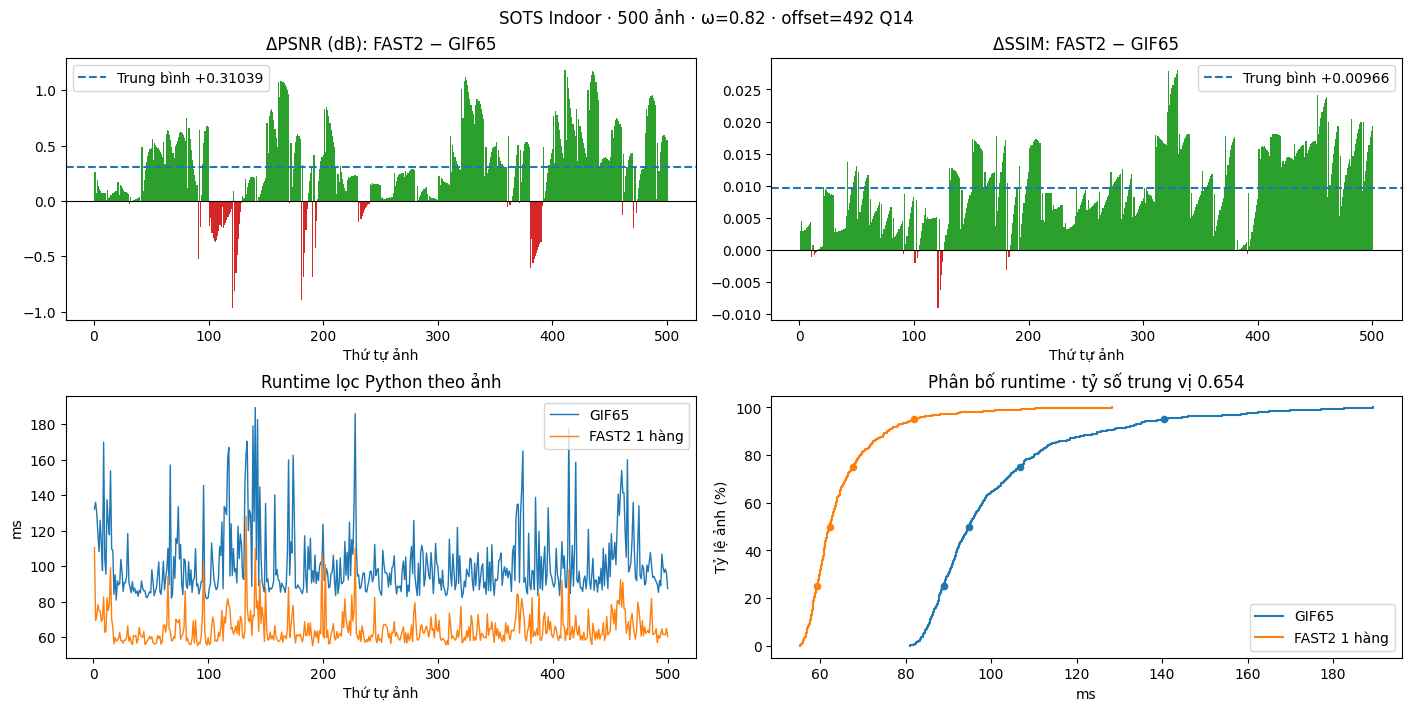

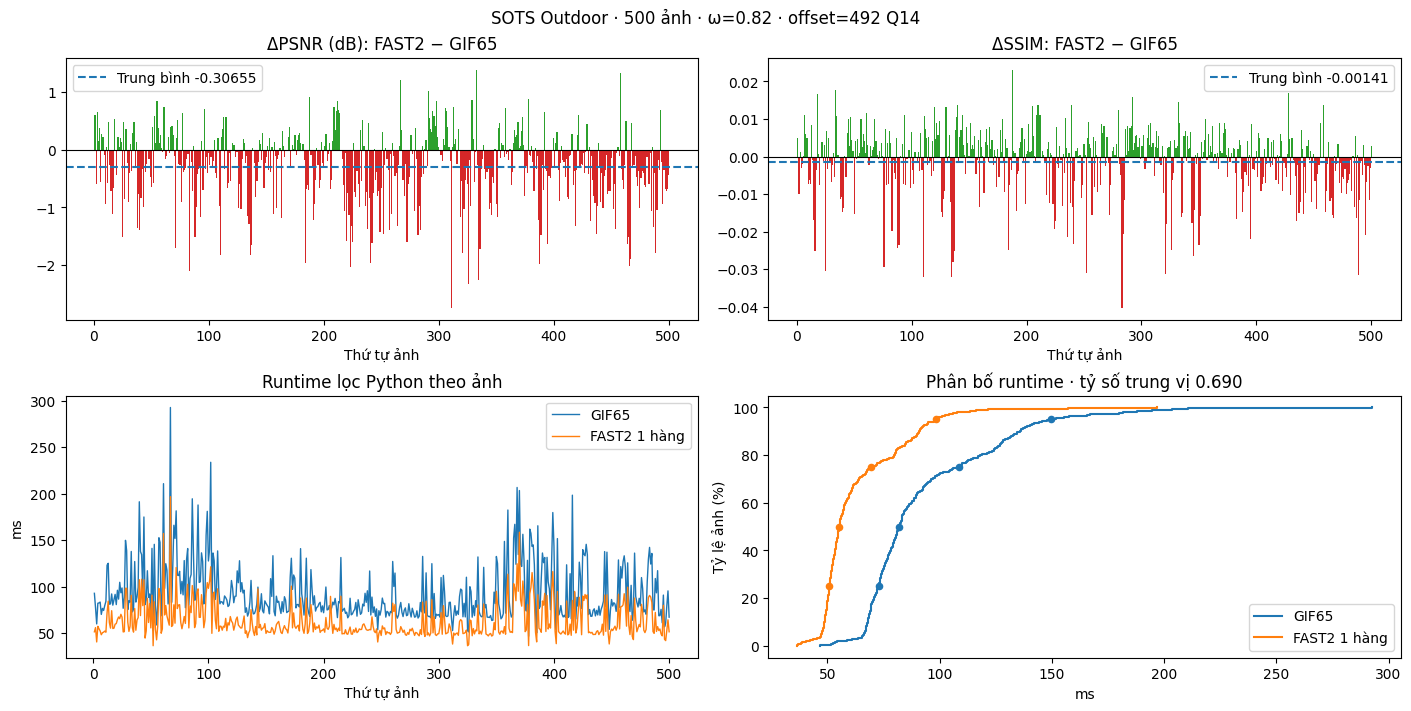

,delta_PSNR,delta_SSIM,worst_PSNR,worst_SSIM,both_improved,losses_over_1dB,median_FAST2_over_GIF
dataset,,,,,,,
Indoor,0.31039,0.00966,-0.96830,-0.00905,421,0,0.65412
Outdoor,-0.30655,-0.00141,-2.74501,-0.04035,139,69,0.68982


P25_ms  P50_ms   P75_ms   P95_ms
dataset method                                        
Indoor  GIF65         88.913  94.766  106.683  140.550
        FAST2 1 hàng  59.381  62.256   67.627   81.872
Outdoor GIF65         72.939  81.786  108.644  149.824
        FAST2 1 hàng  50.924  55.406   69.592   98.248

In [12]:
sots_results = None
if RUN_SOTS and all(p.is_dir() for p in SOTS_ROOTS.values()):
    sots_results = run_sots(SOTS_ROOTS,SAMPLE_LIMIT,REPEATS)
    sots_comparison,sots_percentiles = report_sots(sots_results)
elif RUN_SOTS:  
    print("Sửa SOTS_ROOTS để chạy benchmark:", SOTS_ROOTS)